# MP2 Part 2: Commit activity visualization (rkabarwa)
Aggregates the commits retrieved in Part 1 (`rkabarwa_project_summary.csv`) into monthly time series, plots them, finds the longest inactivity gap per project, and writes `rkabarwa_project_stats.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

netid = "rkabarwa"

df = pd.read_csv(f"{netid}_project_summary.csv", sep=";")
df.columns = ["project", "commit", "author", "time", "message"]
df["Month"] = pd.to_datetime(df["time"], unit="s").dt.strftime("%Y-%m")

projects = pd.read_csv("net2prj.csv")
projects = projects[projects.netID == netid].reset_index(drop=True)
print(len(df), "commits,", df.project.nunique(), "projects")

45985 commits, 10 projects


## Step 1: monthly time series (one CSV per project)
Every month between the first and last commit is included, with 0 for months without commits. Saved as `rkabarwa_commits_timeseries_<WOCProjectID>.csv` with columns `Month;#Commits`.

In [2]:
def monthly_series(prj):
    d = df[df["project"] == prj]
    counts = d.groupby("Month").size().reset_index(name="#Commits")
    counts["time"] = pd.to_datetime(counts["Month"])
    full = pd.DataFrame({"time": pd.date_range(counts["time"].min(),
                                               counts["time"].max(), freq="MS")})
    m = full.merge(counts, on="time", how="left").fillna({"#Commits": 0})
    m["Month"] = m["time"].dt.strftime("%Y-%m")
    m["#Commits"] = m["#Commits"].astype(int)
    return m[["Month", "#Commits"]]

series = {}
for prj in projects.WoC:
    series[prj] = monthly_series(prj)
    series[prj].to_csv(f"{netid}_commits_timeseries_{prj}.csv", sep=";", index=False)
    print(f"{prj}: {len(series[prj])} months, {series[prj]['Month'].iloc[0]} to {series[prj]['Month'].iloc[-1]}")

dlr-rm_blenderproc: 82 months, 2019-06 to 2026-03
riatelab_cartography: 122 months, 2015-06 to 2025-07
patrickzib_sfa: 112 months, 2016-02 to 2025-05
openexoplanetcatalogue_open_exoplanet_catalogue: 179 months, 2011-01 to 2025-11
snakemake-workflows_rna-seq-kallisto-sleuth: 83 months, 2018-12 to 2025-10
brianmanderson_dicom_utilities: 22 months, 2019-10 to 2021-07
iraf-community_iraf: 442 months, 1989-02 to 2025-11
dgerosa_precession: 118 months, 2015-11 to 2025-08
plasmapy_plasmapy: 126 months, 2015-11 to 2026-04
iqusoft_intel-qs: 95 months, 2017-11 to 2025-09


## Step 2: line plots (300 DPI)
Saved as `rkabarwa_timeseries_<WOCProjectID>.png`.

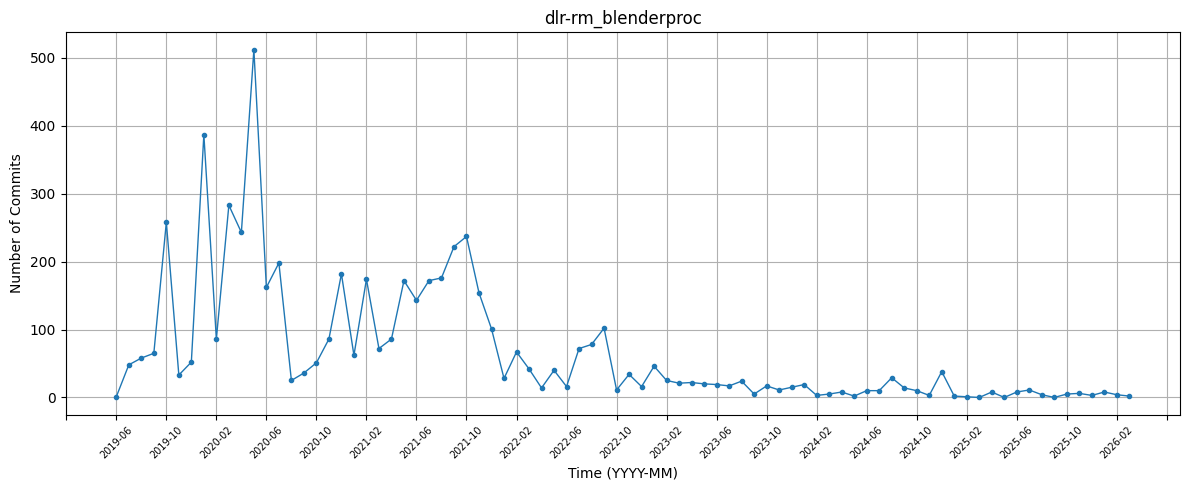

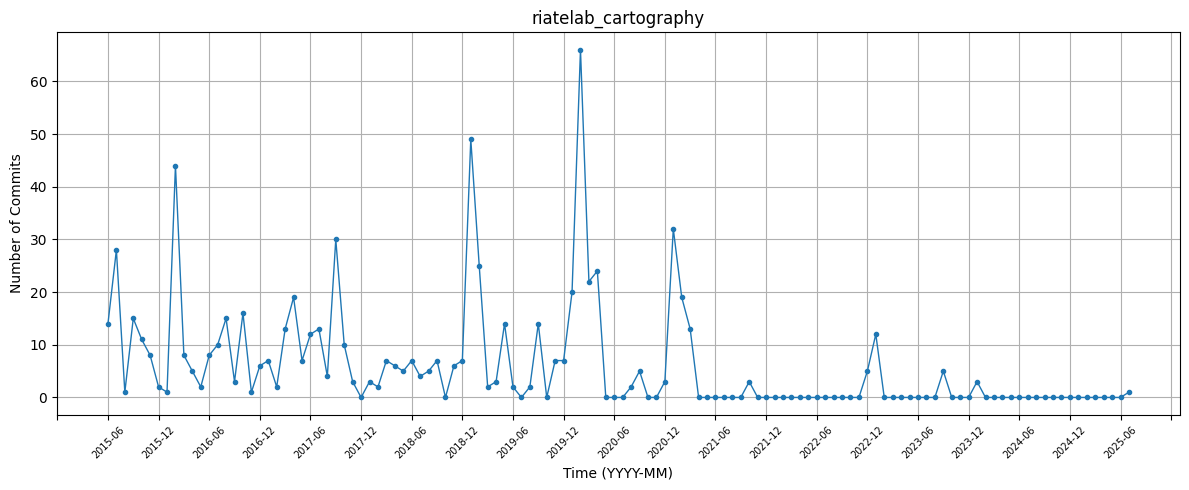

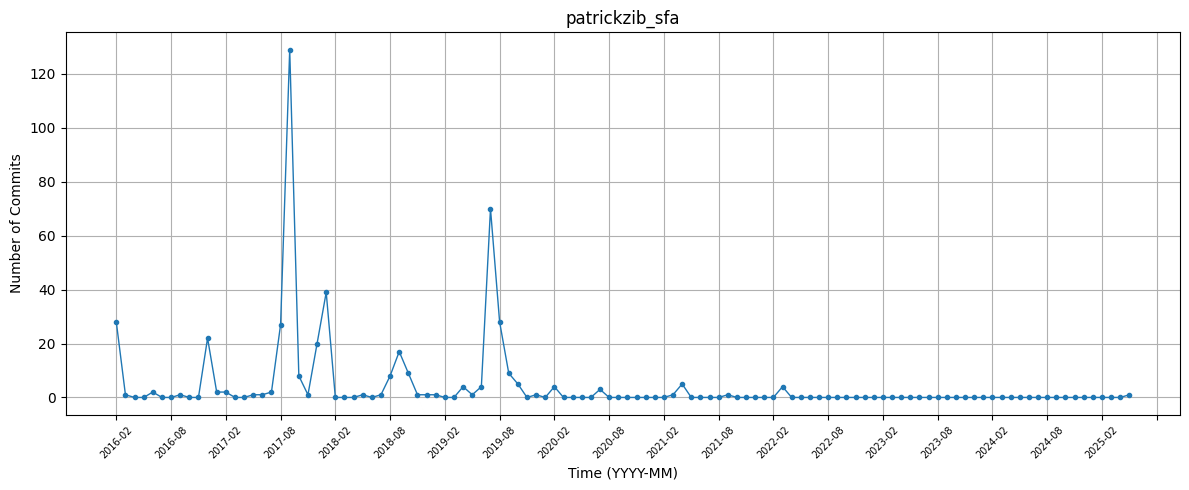

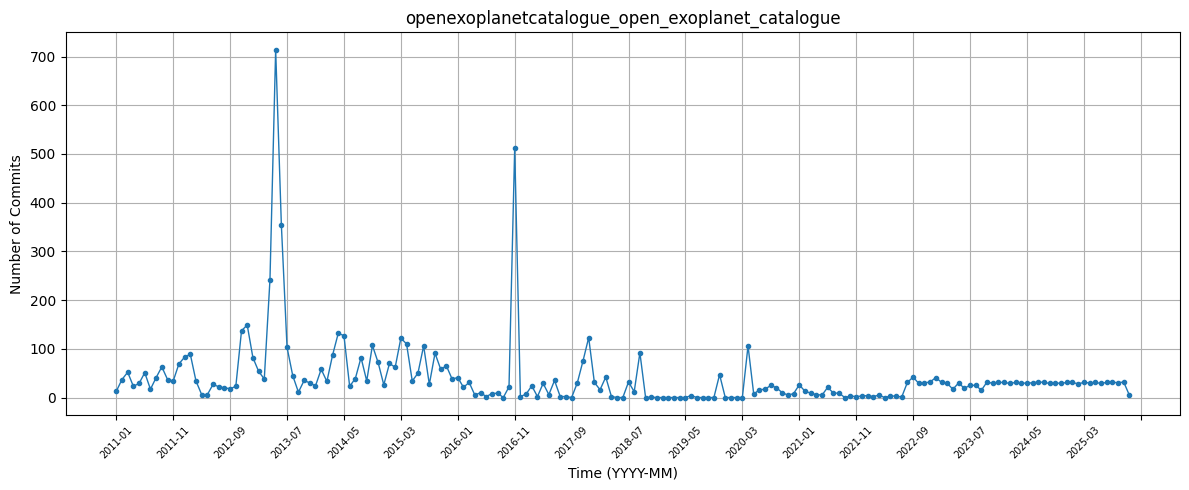

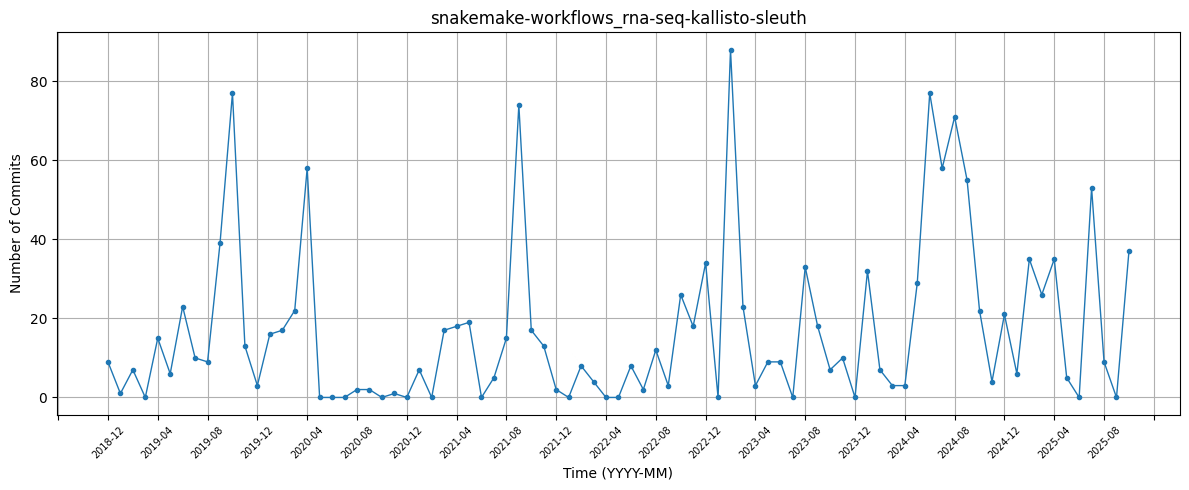

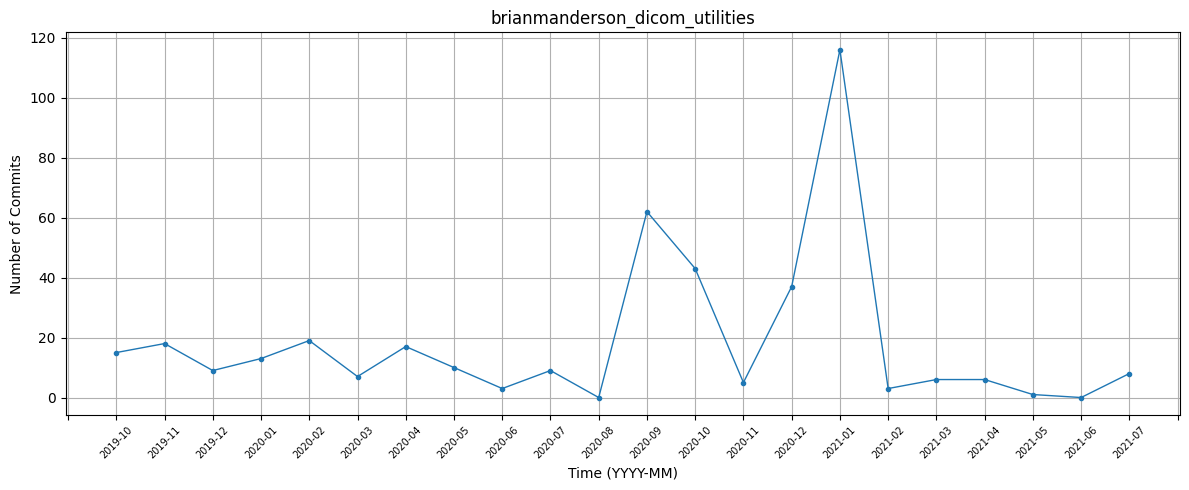

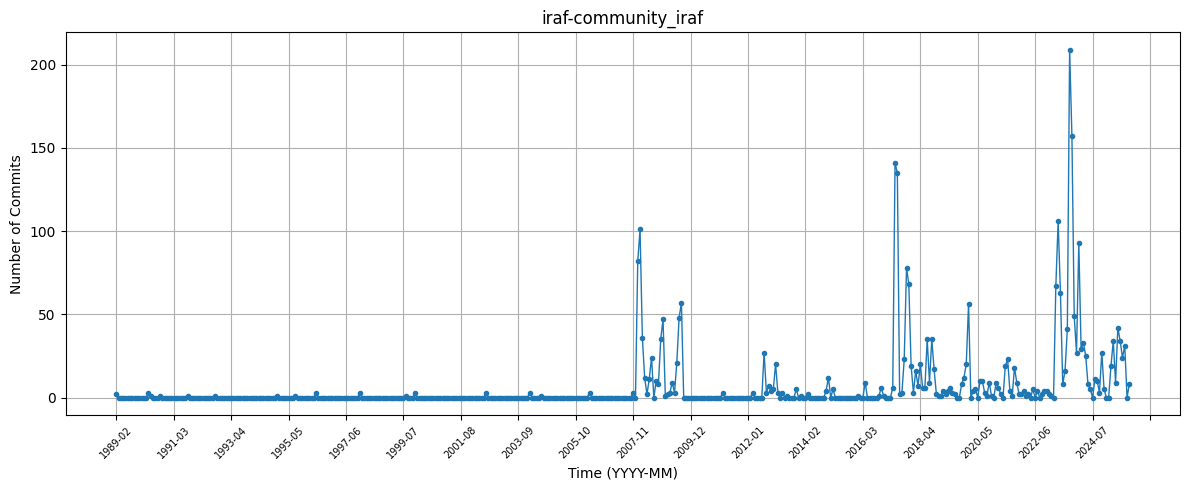

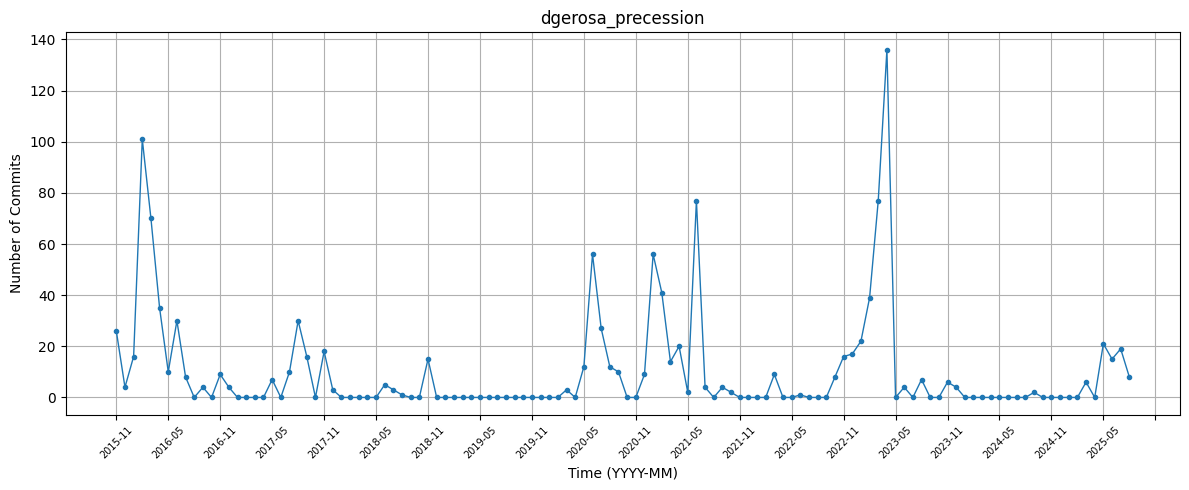

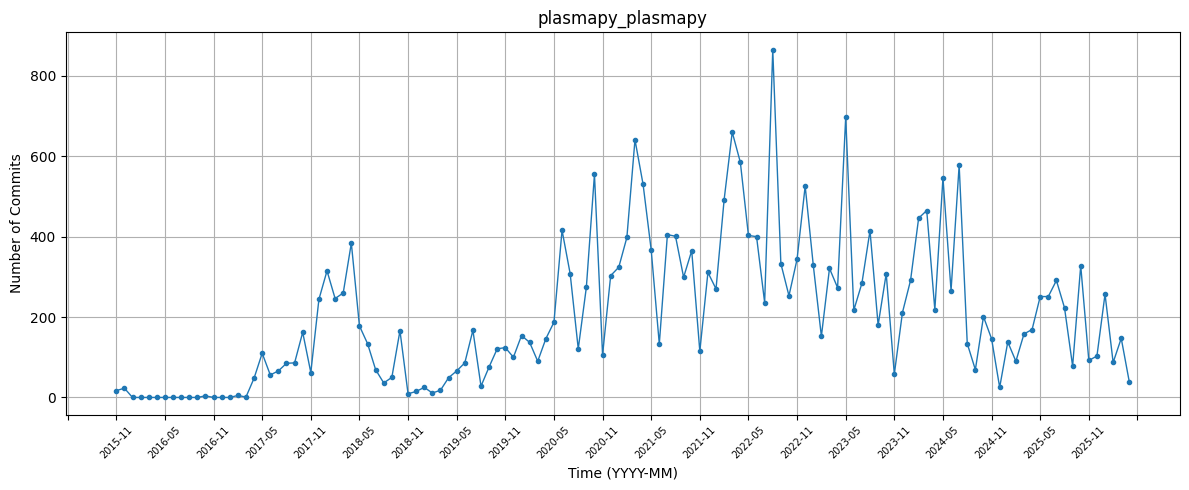

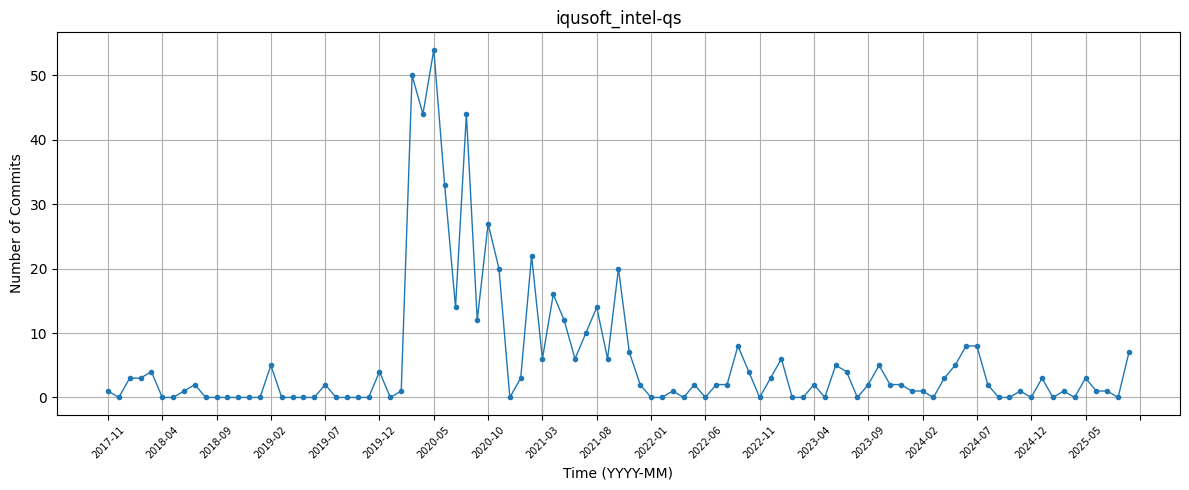

In [3]:
for prj, m in series.items():
    plt.figure(figsize=(12, 5))
    plt.plot(m["Month"], m["#Commits"], marker="o", markersize=3, linestyle="-", linewidth=1)
    plt.xlabel("Time (YYYY-MM)")
    plt.ylabel("Number of Commits")
    plt.title(prj)
    plt.grid(True)
    plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(nbins=24))  # keeps long series readable
    plt.xticks(rotation=45, fontsize=7)
    plt.tight_layout()
    plt.savefig(f"{netid}_timeseries_{prj}.png", dpi=300)
    plt.show()
    plt.close()

## Step 3: longest inactivity gap
A gap is a run of consecutive zero-commit months. The longest gap is reported with inclusive start and end months. `NumCommitsAfterLastGap` counts commits in months after the longest gap ends, and `NumberOfGapsInTimeline` counts gaps of at least three months.

In [4]:
def gap_stats(m, min_gap=3):
    runs, start = [], None            # inclusive (start, end) index runs of zero months
    for i, c in enumerate(m["#Commits"]):
        if c == 0 and start is None:
            start = i
        if c != 0 and start is not None:
            runs.append((start, i - 1)); start = None
    if start is not None:
        runs.append((start, len(m) - 1))
    if not runs:
        return dict(LongestGapStart="N/A", LongestGapEnd="N/A", LongestGapLength=0,
                    NumCommitsAfterLastGap=int(m["#Commits"].sum()), NumberOfGapsInTimeline=0)
    s, e = max(runs, key=lambda r: r[1] - r[0])
    return dict(LongestGapStart=m.loc[s, "Month"], LongestGapEnd=m.loc[e, "Month"],
                LongestGapLength=e - s + 1,
                NumCommitsAfterLastGap=int(m.loc[e + 1:, "#Commits"].sum()),
                NumberOfGapsInTimeline=sum(1 for a, b in runs if b - a + 1 >= min_gap))

gaps = pd.DataFrame({prj: gap_stats(m) for prj, m in series.items()}).T
print(gaps.to_markdown())

|                                                 | LongestGapStart   | LongestGapEnd   |   LongestGapLength |   NumCommitsAfterLastGap |   NumberOfGapsInTimeline |
|:------------------------------------------------|:------------------|:----------------|-------------------:|-------------------------:|-------------------------:|
| dlr-rm_blenderproc                              | 2025-03           | 2025-03         |                  1 |                       59 |                        0 |
| riatelab_cartography                            | 2024-02           | 2025-06         |                 17 |                        1 |                        6 |
| patrickzib_sfa                                  | 2022-04           | 2025-04         |                 37 |                        1 |                        6 |
| openexoplanetcatalogue_open_exoplanet_catalogue | 2018-12           | 2019-05         |                  6 |                     1549 |                        3 |
| snakemak

## Step 4: activity pattern classification
Chosen by inspecting the plots above (steady, rising, declining, U-shaped, cyclical, irregular). Reasoning is in the Interpretation section.

In [5]:
pattern = {
    "dlr-rm_blenderproc": "declining",
    "riatelab_cartography": "declining",
    "patrickzib_sfa": "declining",
    "openexoplanetcatalogue_open_exoplanet_catalogue": "U-shaped",
    "snakemake-workflows_rna-seq-kallisto-sleuth": "steady",
    "brianmanderson_dicom_utilities": "irregular",
    "iraf-community_iraf": "irregular",
    "dgerosa_precession": "cyclical",
    "plasmapy_plasmapy": "rising",
    "iqusoft_intel-qs": "irregular",
}

## Step 5: `rkabarwa_project_stats.csv`
Part 1 columns (WoC commit stats plus GitHub stars, forks, and last commit date collected on 2026-09-28 in `rkabarwa.ipynb`) followed by the Part 2 gap columns and the activity pattern.

In [6]:
woc = df.groupby("project").agg(ncommits=("commit", "count"), nauthors=("author", "nunique"),
                                **{"from": ("time", "min"), "to": ("time", "max")})

gh = pd.DataFrame({  # from the GitHub API cell in rkabarwa.ipynb (collected 2026-09-28)
    "project": projects.WoC,
    "nstars": [3730, 403, 321, 1128, 69, 108, 180, 42, 714, 264],
    "nforks": [519, 44, 67, 224, 48, 32, 54, 18, 374, 76],
    "lastGHCommitDate": ["2026-01-07", "2025-07-23", "2025-05-02", "2026-09-28", "2026-08-17",
                         "2026-09-08", "2026-09-25", "2026-06-06", "2026-09-28", "2026-09-11"],
}).set_index("project")

stats = woc.join(gh).join(gaps)
stats["ActivityPattern"] = pd.Series(pattern)
stats = stats.reindex(projects.WoC).reset_index().rename(columns={"WoC": "Project"})
stats = stats[["Project", "ncommits", "nauthors", "from", "to", "nstars", "nforks", "lastGHCommitDate",
               "LongestGapStart", "LongestGapEnd", "LongestGapLength", "NumCommitsAfterLastGap",
               "ActivityPattern", "NumberOfGapsInTimeline"]]
stats.to_csv(f"{netid}_project_stats.csv", sep=";", index=False)
print(stats.to_markdown(index=False))

| Project                                         |   ncommits |   nauthors |       from |         to |   nstars |   nforks | lastGHCommitDate   | LongestGapStart   | LongestGapEnd   |   LongestGapLength |   NumCommitsAfterLastGap | ActivityPattern   |   NumberOfGapsInTimeline |
|:------------------------------------------------|-----------:|-----------:|-----------:|-----------:|---------:|---------:|:-------------------|:------------------|:----------------|-------------------:|-------------------------:|:------------------|-------------------------:|
| dlr-rm_blenderproc                              |       5512 |        152 | 1561714326 | 1773536613 |     3730 |      519 | 2026-01-07         | 2025-03           | 2025-03         |                  1 |                       59 | declining         |                        0 |
| riatelab_cartography                            |        737 |         20 | 1434011231 | 1753254419 |      403 |       44 | 2025-07-23         | 2024-02      

# Interpretation

Gap counts are gaps of at least three consecutive zero-commit months. Longest gaps are inclusive of start and end months.

- **dlr-rm_blenderproc: declining, 0 gaps.** Peaked in 2020 (2,251 commits) and has fallen every year since, to 48 in 2025. Never quiet for more than one month, so it is maintained but past its build-out phase.
- **riatelab_cartography: declining, 6 gaps.** Steady at 60 to 140 commits per year through 2020, then near zero from 2022. Longest gap 2024-02 to 2025-06 (17 months) with one commit after. Likely matured and superseded.
- **patrickzib_sfa: declining, 6 gaps.** Bursts in 2017 and 2019, then almost nothing. Longest gap 2022-04 to 2025-04 (37 months) with one commit after. Looks like research code abandoned after its papers.
- **openexoplanetcatalogue_open_exoplanet_catalogue: U-shaped, 3 gaps.** Peak of 1,733 commits in 2013, trough of 51 in 2019 (longest gap 2018-12 to 2019-05, 6 months), recovery to about 300 per year in 2023 to 2025. Recent commits land at the same time each day, suggesting automated updates.
- **snakemake-workflows_rna-seq-kallisto-sleuth: steady, 1 gap.** 115 to 382 commits every year since 2019; only gap is 2020-05 to 2020-07. Continuously maintained pipeline.
- **brianmanderson_dicom_utilities: irregular, 0 gaps.** WoC covers only 2019-10 to 2021-07, with bursts up to 116 commits in 2021-01. GitHub shows a commit in 2026-09, so the project outlived WoC coverage.
- **iraf-community_iraf: irregular, 23 gaps.** History from 1989 with 294 of 442 months empty. Activity comes in bursts (2008, 2017, 2023 with 744 commits). Longest gap 2000-01 to 2002-06 (30 months). Imported legacy history plus episodic revivals.
- **dgerosa_precession: cyclical, 7 gaps.** Bursts every two to three years (2016, 2020 to 2021, 2023, 2025) separated by near-zero years. Longest gap 2018-12 to 2020-02 (15 months). Consistent with release-driven scientific software.
- **plasmapy_plasmapy: rising, 2 gaps.** Grew from 925 commits in 2017 to a 5,367 peak in 2022 and stays in the thousands. Longest gap (2016-01 to 2016-09) was at the project's start.
- **iqusoft_intel-qs: irregular, 3 gaps.** One burst of 299 commits in 2020, otherwise 1 to 29 per year. Longest gap 2018-08 to 2019-01 (6 months). A single development push followed by light maintenance.

Data note: commit times are WoC author timestamps, so some series extend past the README's stated January 2025 coverage. Each series ends at the project's last commit in `rkabarwa_project_summary.csv`.